In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("loan_approved.csv")

In [3]:
df

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


# Basic Checks

In [5]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [6]:
df.tail()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y
613,LP002990,Female,No,0,Graduate,Yes,4583,0.0,133.0,360.0,0.0,Semiurban,N


In [7]:
df.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area',
       'Loan_Status (Approved)'],
      dtype='object')

In [8]:
df.rename(columns={"Loan_Status (Approved)":"Loan_Status"}, inplace= True)

In [9]:
new_columns = []  # Plural name
for col in df.columns:
    new_columns.append(str(col).lower())
df.columns = new_columns
df.columns

Index(['loan_id', 'gender', 'married', 'dependents', 'education',
       'self_employed', 'applicantincome', 'coapplicantincome', 'loanamount',
       'loan_amount_term', 'credit_history', 'property_area', 'loan_status'],
      dtype='object')

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   loan_id            614 non-null    object 
 1   gender             601 non-null    object 
 2   married            611 non-null    object 
 3   dependents         599 non-null    object 
 4   education          614 non-null    object 
 5   self_employed      582 non-null    object 
 6   applicantincome    614 non-null    int64  
 7   coapplicantincome  614 non-null    float64
 8   loanamount         592 non-null    float64
 9   loan_amount_term   600 non-null    float64
 10  credit_history     564 non-null    float64
 11  property_area      614 non-null    object 
 12  loan_status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [11]:
df.gender.unique()

array(['Male', 'Female', nan], dtype=object)

In [12]:
df.gender.value_counts()

gender
Male      489
Female    112
Name: count, dtype: int64

In [13]:
df.gender.dtype

dtype('O')

In [14]:
for i in df:
    print(i)

loan_id
gender
married
dependents
education
self_employed
applicantincome
coapplicantincome
loanamount
loan_amount_term
credit_history
property_area
loan_status


In [15]:
for i in df:
    if len(df[i].unique()) <= 20:
        print(i,":",df[i].unique())

gender : ['Male' 'Female' nan]
married : ['No' 'Yes' nan]
dependents : ['0' '1' '2' '3+' nan]
education : ['Graduate' 'Not Graduate']
self_employed : ['No' 'Yes' nan]
loan_amount_term : [360. 120. 240.  nan 180.  60. 300. 480.  36.  84.  12.]
credit_history : [ 1.  0. nan]
property_area : ['Urban' 'Rural' 'Semiurban']
loan_status : ['Y' 'N']


In [16]:
for i in df:
    if len(df[i].unique()) <= 20:
        print(df[i].value_counts())
        print("=========================")

gender
Male      489
Female    112
Name: count, dtype: int64
married
Yes    398
No     213
Name: count, dtype: int64
dependents
0     345
1     102
2     101
3+     51
Name: count, dtype: int64
education
Graduate        480
Not Graduate    134
Name: count, dtype: int64
self_employed
No     500
Yes     82
Name: count, dtype: int64
loan_amount_term
360.0    512
180.0     44
480.0     15
300.0     13
240.0      4
84.0       4
120.0      3
60.0       2
36.0       2
12.0       1
Name: count, dtype: int64
credit_history
1.0    475
0.0     89
Name: count, dtype: int64
property_area
Semiurban    233
Urban        202
Rural        179
Name: count, dtype: int64
loan_status
Y    422
N    192
Name: count, dtype: int64


In [17]:
for i in df:
    if df[i].dtype == "O" and len(df[i].unique()) <= 20:
        print(i,":",df[i].unique())

gender : ['Male' 'Female' nan]
married : ['No' 'Yes' nan]
dependents : ['0' '1' '2' '3+' nan]
education : ['Graduate' 'Not Graduate']
self_employed : ['No' 'Yes' nan]
property_area : ['Urban' 'Rural' 'Semiurban']
loan_status : ['Y' 'N']


In [18]:
df.gender.isnull().sum()

13

In [19]:
df.loc[df.gender.isnull(),["gender"]]

,gender
23,NaN
126,NaN
171,NaN
188,NaN
314,NaN
334,NaN
460,NaN
467,NaN
477,NaN
507,NaN


In [20]:
df.loc[df.gender.isnull(),["gender"]] = "Male"

In [21]:
df.gender.unique()

array(['Male', 'Female'], dtype=object)

In [22]:
df.married.value_counts()

married
Yes    398
No     213
Name: count, dtype: int64

In [23]:
df.married.unique()

array(['No', 'Yes', nan], dtype=object)

In [24]:
df.self_employed.unique()

array(['No', 'Yes', nan], dtype=object)

In [25]:
df.self_employed.value_counts()

self_employed
No     500
Yes     82
Name: count, dtype: int64

In [26]:
 df.describe()

,applicantincome,coapplicantincome,loanamount,loan_amount_term,credit_history
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [27]:
df.describe(include= "O")

,loan_id,gender,married,dependents,education,self_employed,property_area,loan_status
count,614,614,611,599,614,582,614,614
unique,614,2,2,4,2,2,3,2
top,LP001002,Male,Yes,0,Graduate,No,Semiurban,Y
freq,1,502,398,345,480,500,233,422


In [28]:
df.loanamount.median()

128.0

In [29]:
df.loc[df.loanamount.isnull(), ["loanamount"]] = df.loanamount.median()

In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   loan_id            614 non-null    object 
 1   gender             614 non-null    object 
 2   married            611 non-null    object 
 3   dependents         599 non-null    object 
 4   education          614 non-null    object 
 5   self_employed      582 non-null    object 
 6   applicantincome    614 non-null    int64  
 7   coapplicantincome  614 non-null    float64
 8   loanamount         614 non-null    float64
 9   loan_amount_term   600 non-null    float64
 10  credit_history     564 non-null    float64
 11  property_area      614 non-null    object 
 12  loan_status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [31]:
df.groupby("property_area").max("loanamount")

,applicantincome,coapplicantincome,loanamount,loan_amount_term,credit_history
property_area,,,,,
Rural,81000,8333.0,570.0,480.0,1.0
Semiurban,39999,20000.0,600.0,480.0,1.0
Urban,63337,41667.0,700.0,480.0,1.0


## EDA

### Univariate Analysis

In [34]:
df.head()

,loan_id,gender,married,dependents,education,self_employed,applicantincome,coapplicantincome,loanamount,loan_amount_term,credit_history,property_area,loan_status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,128.0,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


<Axes: xlabel='gender', ylabel='count'>

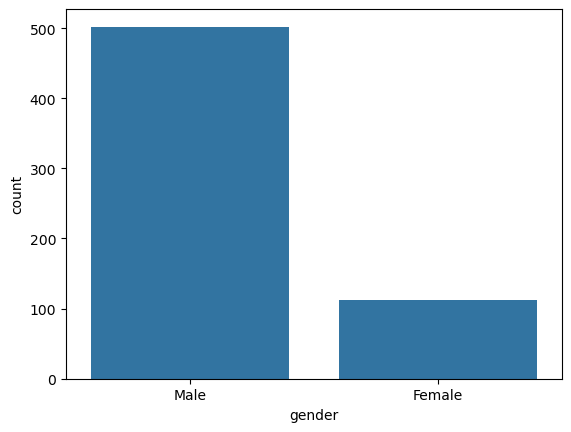

In [35]:
sns.countplot(x = df.gender)

In [36]:
categorical = []

for i in df:
    if len(df[i].unique()) <= 20:
       categorical.append(i)     

In [37]:
categorical

['gender',
 'married',
 'dependents',
 'education',
 'self_employed',
 'loan_amount_term',
 'credit_history',
 'property_area',
 'loan_status']

In [38]:
continuous = []

for i in df:
    if len(df[i].unique()) >= 20:
       continuous.append(i)  

In [39]:
continuous

['loan_id', 'applicantincome', 'coapplicantincome', 'loanamount']

In [40]:
df_cat = df[categorical]
df_cat.head()

,gender,married,dependents,education,self_employed,loan_amount_term,credit_history,property_area,loan_status
0,Male,No,0,Graduate,No,360.0,1.0,Urban,Y
1,Male,Yes,1,Graduate,No,360.0,1.0,Rural,N
2,Male,Yes,0,Graduate,Yes,360.0,1.0,Urban,Y
3,Male,Yes,0,Not Graduate,No,360.0,1.0,Urban,Y
4,Male,No,0,Graduate,No,360.0,1.0,Urban,Y


In [41]:
df_cont = df[continuous]
df_cont.head()

,loan_id,applicantincome,coapplicantincome,loanamount
0,LP001002,5849,0.0,128.0
1,LP001003,4583,1508.0,128.0
2,LP001005,3000,0.0,66.0
3,LP001006,2583,2358.0,120.0
4,LP001008,6000,0.0,141.0


In [42]:
df_cont = df_cont.drop(columns = "loan_id")
df_cont

,applicantincome,coapplicantincome,loanamount
0,5849,0.0,128.0
1,4583,1508.0,128.0
2,3000,0.0,66.0
3,2583,2358.0,120.0
4,6000,0.0,141.0
...,...,...,...
609,2900,0.0,71.0
610,4106,0.0,40.0
611,8072,240.0,253.0
612,7583,0.0,187.0


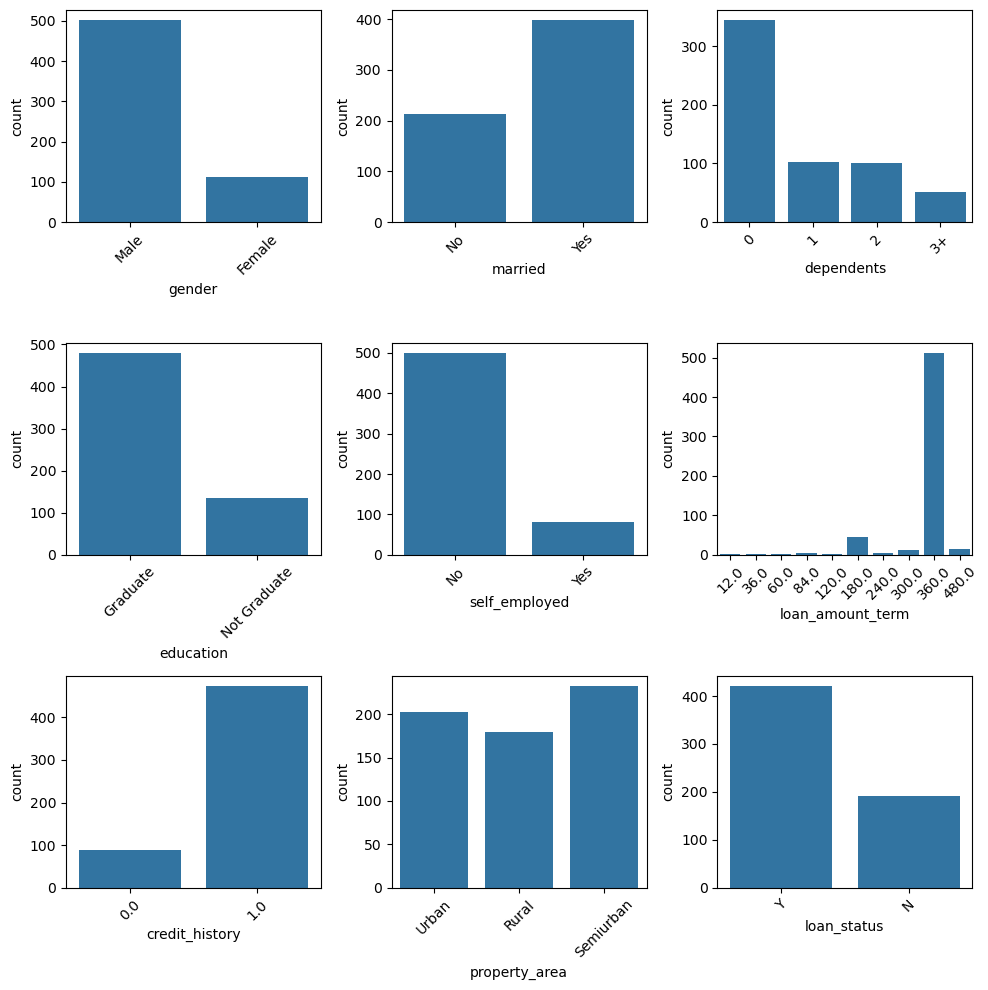

In [43]:
plot_number = 1

plt.figure(figsize= (10,10))
for i in df_cat:
    plt.subplot(3,3,plot_number)
    sns.countplot(x = df_cat[i])
    plt.xticks(rotation = 45)
    plot_number += 1
plt.tight_layout() 

### Insights

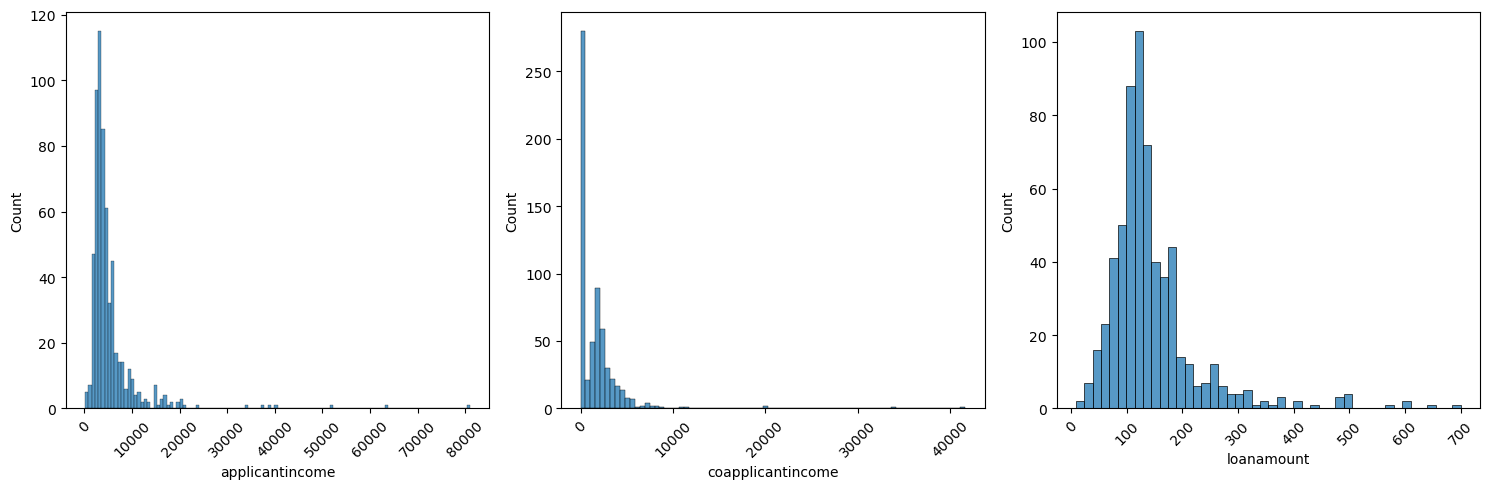

In [45]:
plot_number = 1

plt.figure(figsize= (15,5))
for i in df_cont:
    plt.subplot(1,3,plot_number)
    sns.histplot(x = df_cont[i])
    plt.xticks(rotation = 45)
    plot_number += 1
plt.tight_layout() 

### Bivariate Analysis

In [47]:
pd.crosstab(df["gender"], df["loan_status"])

loan_status,N,Y
gender,,
Female,37,75
Male,155,347


In [48]:
pd.crosstab(df["gender"],df["loan_status"],normalize="index") * 100

loan_status,N,Y
gender,,
Female,33.035714,66.964286
Male,30.876494,69.123506


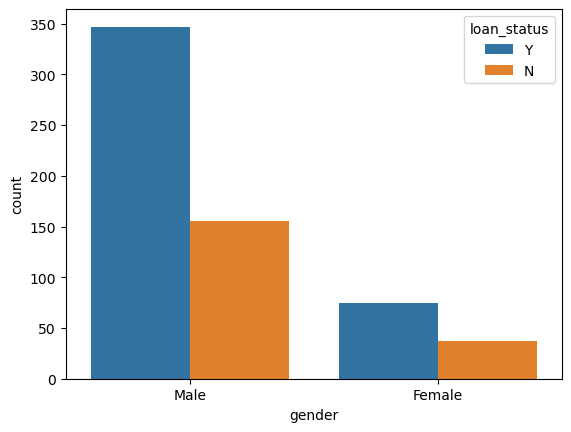

In [49]:
sns.countplot(data=df, x= "gender", hue="loan_status")
plt.show()

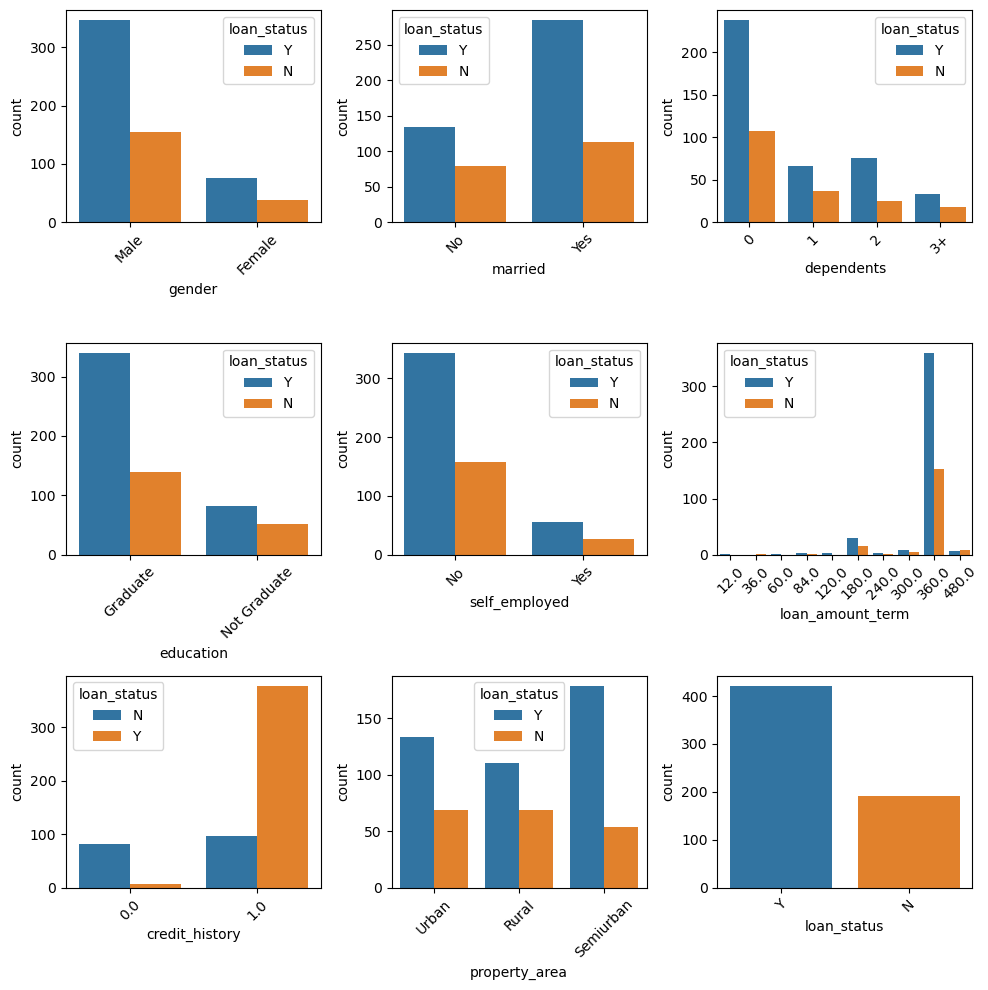

In [50]:
plot_number = 1

plt.figure(figsize= (10,10))
for i in df_cat:
    plt.subplot(3,3,plot_number)
    sns.countplot(x = df_cat[i], hue = df.loan_status)
    plt.xticks(rotation = 45)
    plot_number += 1
plt.tight_layout() 

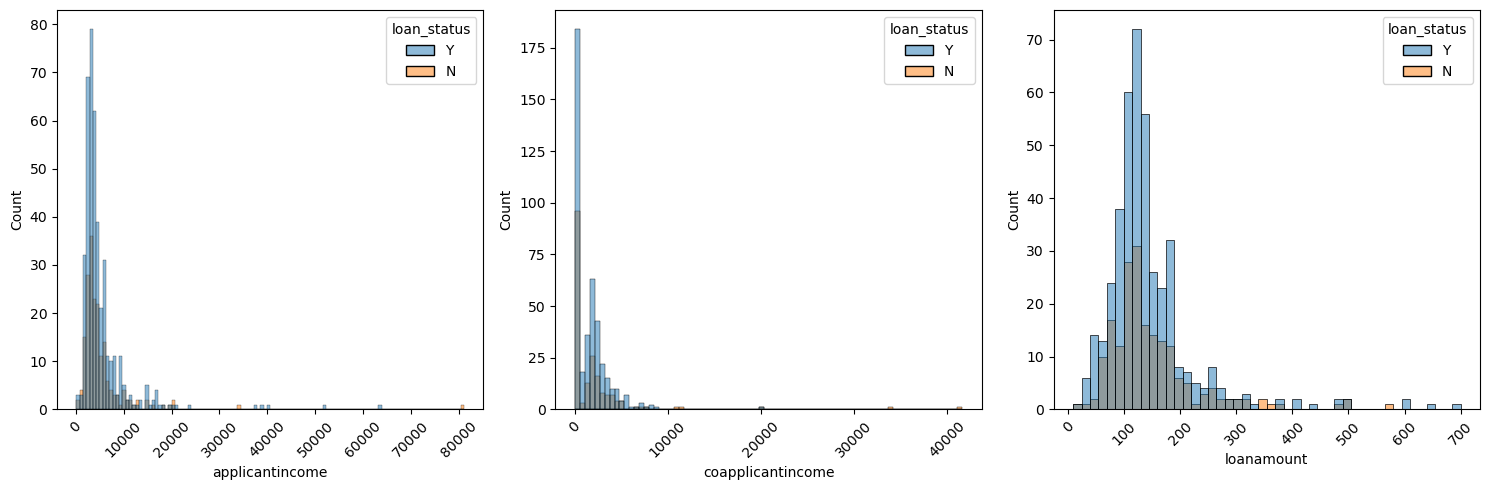

In [51]:
plot_number = 1

plt.figure(figsize= (15,5))
for i in df_cont:
    plt.subplot(1,3, plot_number)
    sns.histplot( x = df_cont[i], hue = df.loan_status)
    plt.xticks(rotation = 45)
    plot_number += 1
plt.tight_layout()

# Data Cleaning

## Handling with Null Values

In [54]:
df.loc[df.gender.isnull(),["gender"]]

,gender


In [55]:
df.gender.isnull().sum()

0

In [56]:
df.isnull().sum()

loan_id               0
gender                0
married               3
dependents           15
education             0
self_employed        32
applicantincome       0
coapplicantincome     0
loanamount            0
loan_amount_term     14
credit_history       50
property_area         0
loan_status           0
dtype: int64

In [57]:
df.describe(include = "O")

,loan_id,gender,married,dependents,education,self_employed,property_area,loan_status
count,614,614,611,599,614,582,614,614
unique,614,2,2,4,2,2,3,2
top,LP001002,Male,Yes,0,Graduate,No,Semiurban,Y
freq,1,502,398,345,480,500,233,422


In [58]:
df.loc[df.married.isnull(),"married"] = "Yes"

In [59]:
df.loc[df.dependents.isnull(),"dependents"] = "0"

In [60]:
df.loc[df.self_employed.isnull(),"self_employed"] = "No"

In [61]:
df.loc[df.property_area.isnull(),"property_area"] = "Semiurban"

In [62]:
df.loc[df.loan_amount_term.isnull(), "loan_amount_term"] = 360.0

In [63]:
df.credit_history.value_counts()

credit_history
1.0    475
0.0     89
Name: count, dtype: int64

In [64]:
df.loc[df.credit_history.isnull(), "credit_history"] = 1.0

In [65]:
df

,loan_id,gender,married,dependents,education,self_employed,applicantincome,coapplicantincome,loanamount,loan_amount_term,credit_history,property_area,loan_status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,128.0,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


### checking with duplicates

In [67]:
df.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
609    False
610    False
611    False
612    False
613    False
Length: 614, dtype: bool

In [68]:
df.duplicated().sum()

0

In [69]:
df[df.duplicated()]

,loan_id,gender,married,dependents,education,self_employed,applicantincome,coapplicantincome,loanamount,loan_amount_term,credit_history,property_area,loan_status


### Exporting Data

In [71]:
df.to_csv("loan_approved_clean.csv")

In [72]:
print(df.shape)
print(df['loan_id'].nunique())
print(df['loan_id'].duplicated().sum())

(614, 13)
614
0


In [195]:
df.to_csv("loan_cleaned.csv", index=False)

In [197]:
pd.read_csv("loan_approved_clean.csv")

,Unnamed: 0,loan_id,gender,married,dependents,education,self_employed,applicantincome,coapplicantincome,loanamount,loan_amount_term,credit_history,property_area,loan_status
0,0,LP001002,Male,No,0,Graduate,No,5849,0.0,128.0,360.0,1.0,Urban,Y
1,1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


In [199]:
test = pd.read_csv("loan_cleaned.csv")

print(test.shape)
print(test['loan_id'].nunique())

(614, 13)
614


In [201]:
df.to_csv("loan_cleaned.csv", index=False)

test = pd.read_csv("loan_cleaned.csv")

print("CSV shape:", test.shape)
print("CSV unique IDs:", test["loan_id"].nunique())

CSV shape: (614, 13)
CSV unique IDs: 614


In [203]:
numeric_cols = [
    'dependents',
    'applicantincome',
    'coapplicantincome',
    'loanamount',
    'loan_amount_term',
    'credit_history'
]

for col in numeric_cols:
    temp = pd.to_numeric(test[col], errors='coerce')
    
    print(
        col,
        "original non-null =", test[col].notna().sum(),
        "numeric =", temp.notna().sum(),
        "non-numeric =", test[col].notna().sum() - temp.notna().sum()
    )

dependents original non-null = 614 numeric = 563 non-numeric = 51
applicantincome original non-null = 614 numeric = 614 non-numeric = 0
coapplicantincome original non-null = 614 numeric = 614 non-numeric = 0
loanamount original non-null = 614 numeric = 614 non-numeric = 0
loan_amount_term original non-null = 614 numeric = 614 non-numeric = 0
credit_history original non-null = 614 numeric = 614 non-numeric = 0


In [205]:
df['applicantincome'].describe()

count      614.000000
mean      5403.459283
std       6109.041673
min        150.000000
25%       2877.500000
50%       3812.500000
75%       5795.000000
max      81000.000000
Name: applicantincome, dtype: float64

In [207]:
df['loanamount'].describe()

count    614.000000
mean     145.752443
std       84.107233
min        9.000000
25%      100.250000
50%      128.000000
75%      164.750000
max      700.000000
Name: loanamount, dtype: float64

## 1. Categorical × Categorical

In [74]:
categorical_cols = [
    "gender",
    "married",
    "dependents",
    "education",
    "self_employed",
    "loan_amount_term",
    "credit_history",
    "property_area"
]

for col in categorical_cols:
    print(col.upper()," vs LOAN STATUS")
    print(pd.crosstab(df[col], df["loan_status"], normalize="index") * 100)

GENDER  vs LOAN STATUS
loan_status          N          Y
gender                           
Female       33.035714  66.964286
Male         30.876494  69.123506
MARRIED  vs LOAN STATUS
loan_status          N          Y
married                          
No           37.089202  62.910798
Yes          28.179551  71.820449
DEPENDENTS  vs LOAN STATUS
loan_status          N          Y
dependents                       
0            31.388889  68.611111
1            35.294118  64.705882
2            24.752475  75.247525
3+           35.294118  64.705882
EDUCATION  vs LOAN STATUS
loan_status           N          Y
education                         
Graduate      29.166667  70.833333
Not Graduate  38.805970  61.194030
SELF_EMPLOYED  vs LOAN STATUS
loan_status            N          Y
self_employed                      
No             31.203008  68.796992
Yes            31.707317  68.292683
LOAN_AMOUNT_TERM  vs LOAN STATUS
loan_status                N           Y
loan_amount_term                    

### 2. Categorical × Continuous

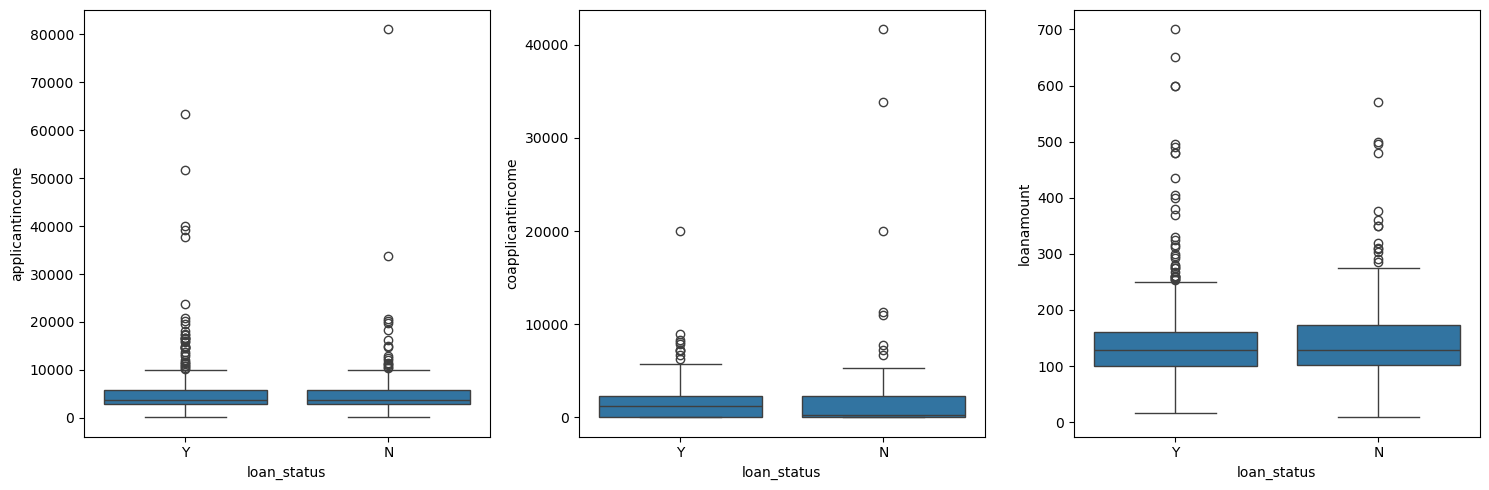

In [76]:
plot_number = 1

plt.figure(figsize= (15,5))
for i in df_cont:
    plt.subplot(1,3, plot_number)
    sns.boxplot(
    data=df,
    x="loan_status",
    y=  df_cont[i]
)
    plot_number += 1
plt.tight_layout()

### Loan Status vs Applicant Income

In [78]:
df.groupby("loan_status")["applicantincome"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

,count,mean,median,std,min,max
loan_status,,,,,,
N,192,5446.078125,3833.5,6819.558528,150,81000
Y,422,5384.068720,3812.5,5765.441615,210,63337


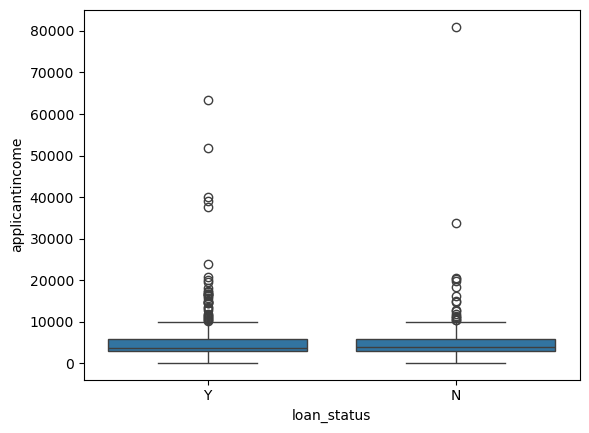

In [79]:
sns.boxplot(
    data=df,
    x="loan_status",
    y="applicantincome"
)
plt.show()

### for Loan Amount

In [81]:
df.groupby("loan_status")["loanamount"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

,count,mean,median,std,min,max
loan_status,,,,,,
N,192,149.890625,128.0,83.529056,9.0,570.0
Y,422,143.869668,128.0,84.400468,17.0,700.0


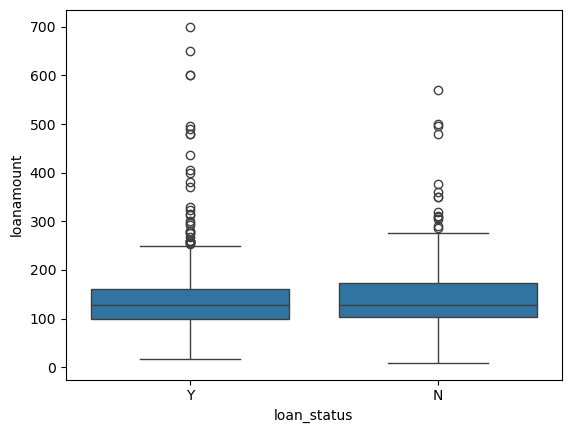

In [82]:
sns.boxplot(data = df, x= "loan_status", y = "loanamount")
plt.show()

### Coapplicant Income

In [84]:
df.groupby("loan_status")["coapplicantincome"].agg(["count","mean","median","std","min","max"])

,count,mean,median,std,min,max
loan_status,,,,,,
N,192,1877.807292,268.0,4384.060103,0.0,41667.0
Y,422,1504.516398,1239.5,1924.754855,0.0,20000.0


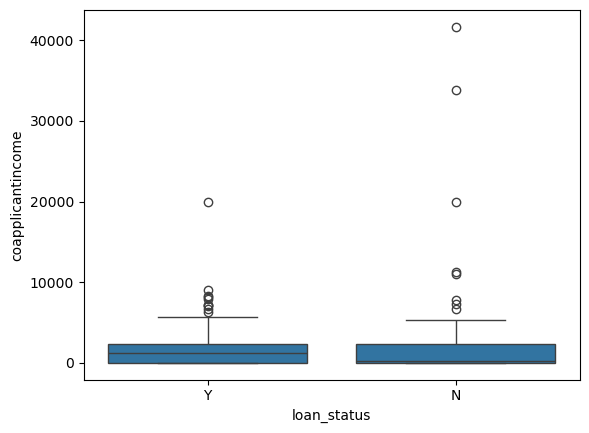

In [85]:
sns.boxplot(
    data= df,
    x = "loan_status",
    y = "coapplicantincome"
)
plt.show()

### 3. Categorical × Continuous — Other Useful Questions

C:\Users\Administrator\AppData\Local\Temp\ipykernel_10840\3291671249.py:4: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(10, 10))


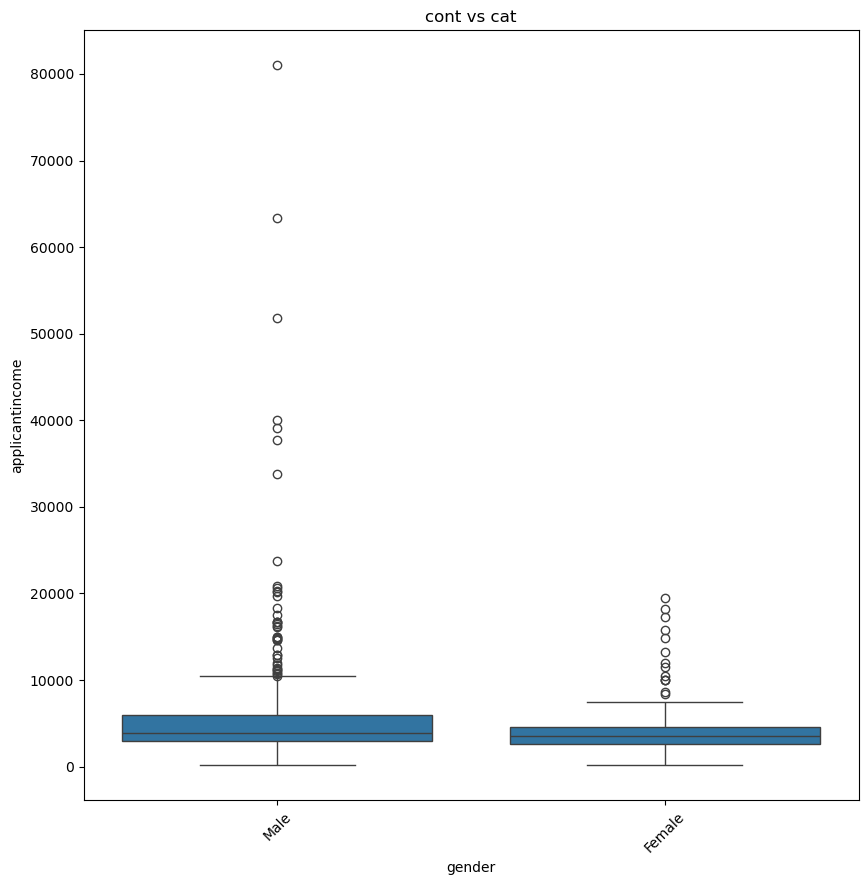

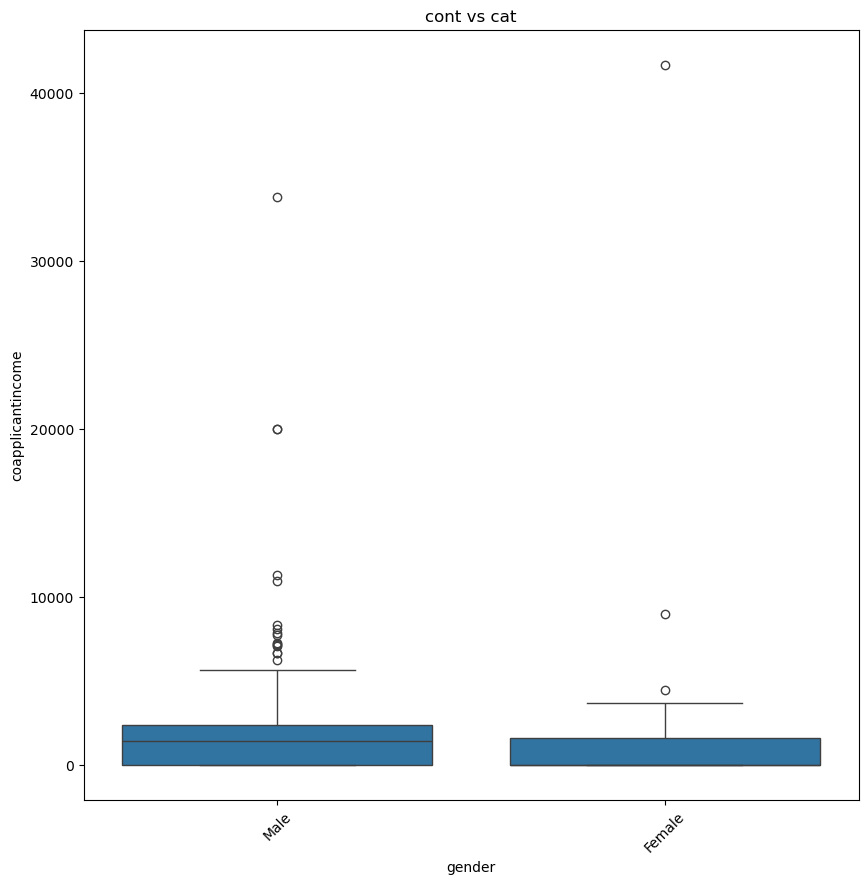

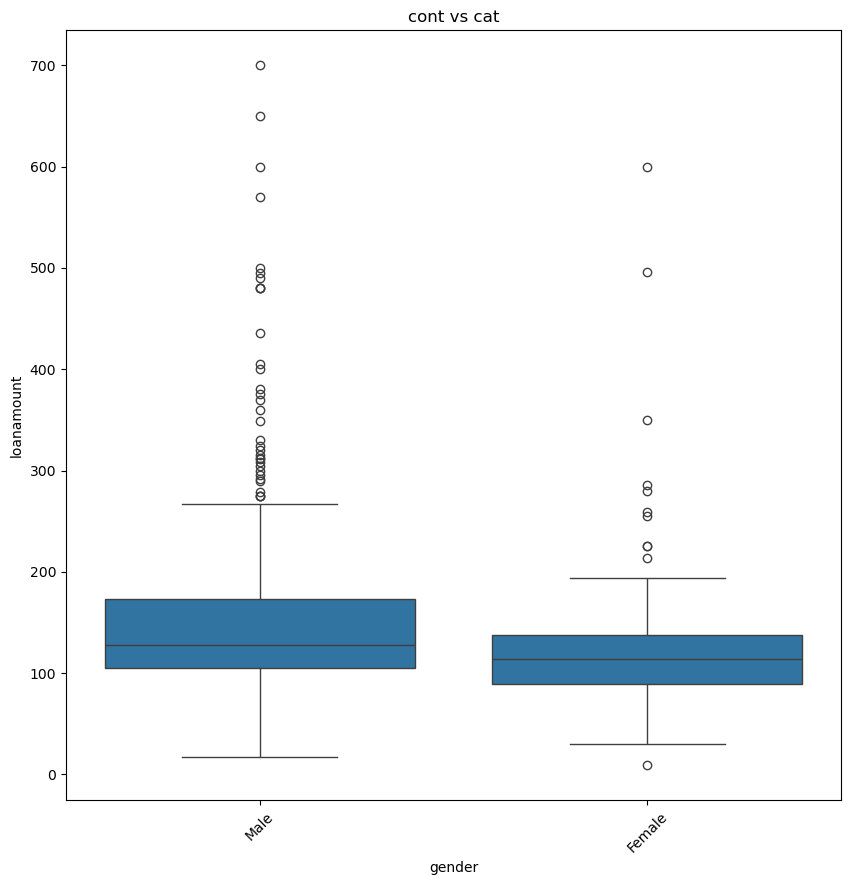

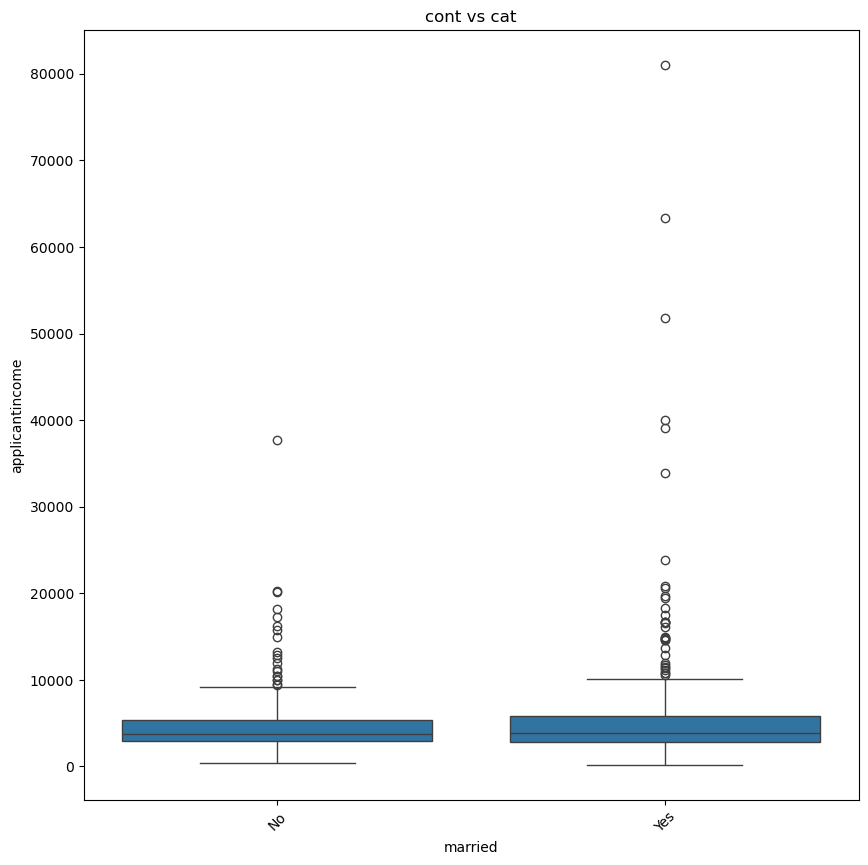

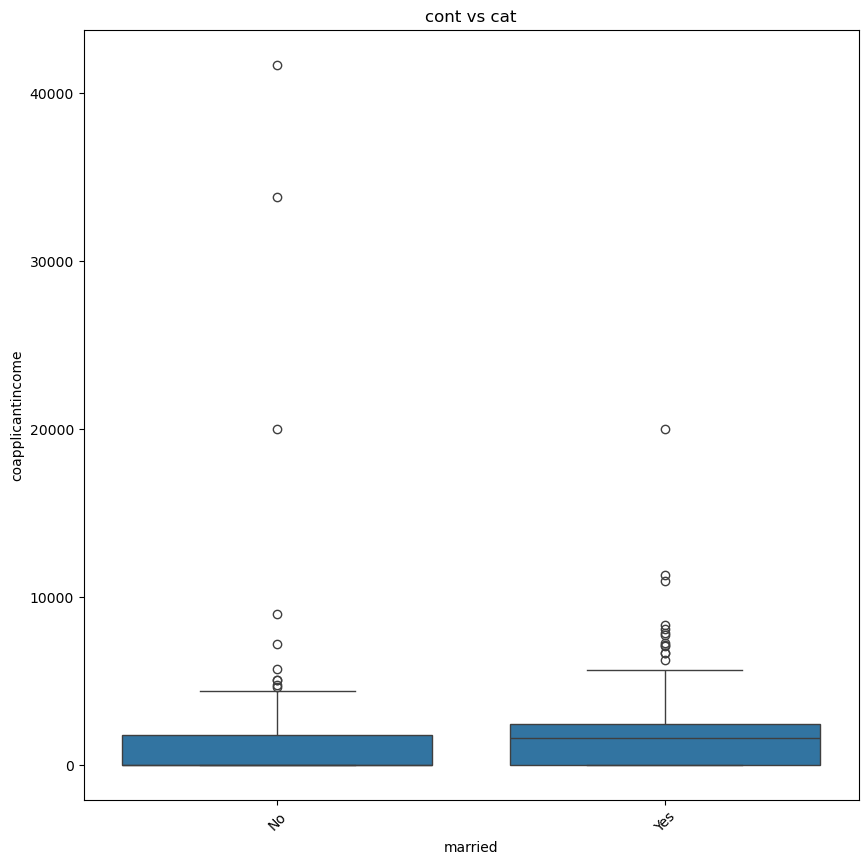

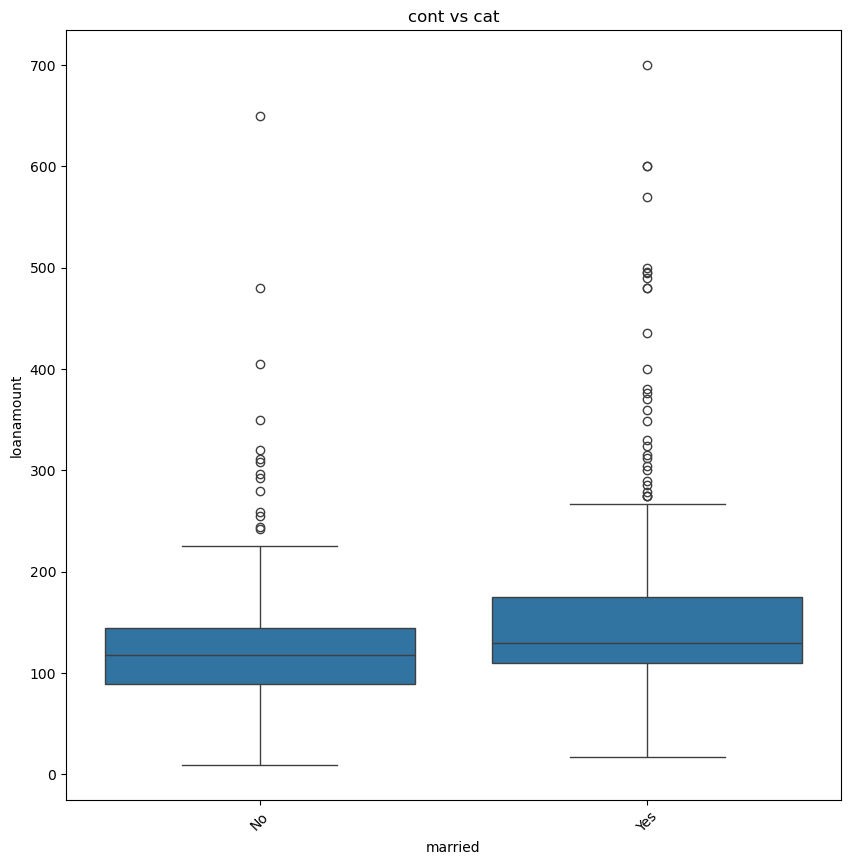

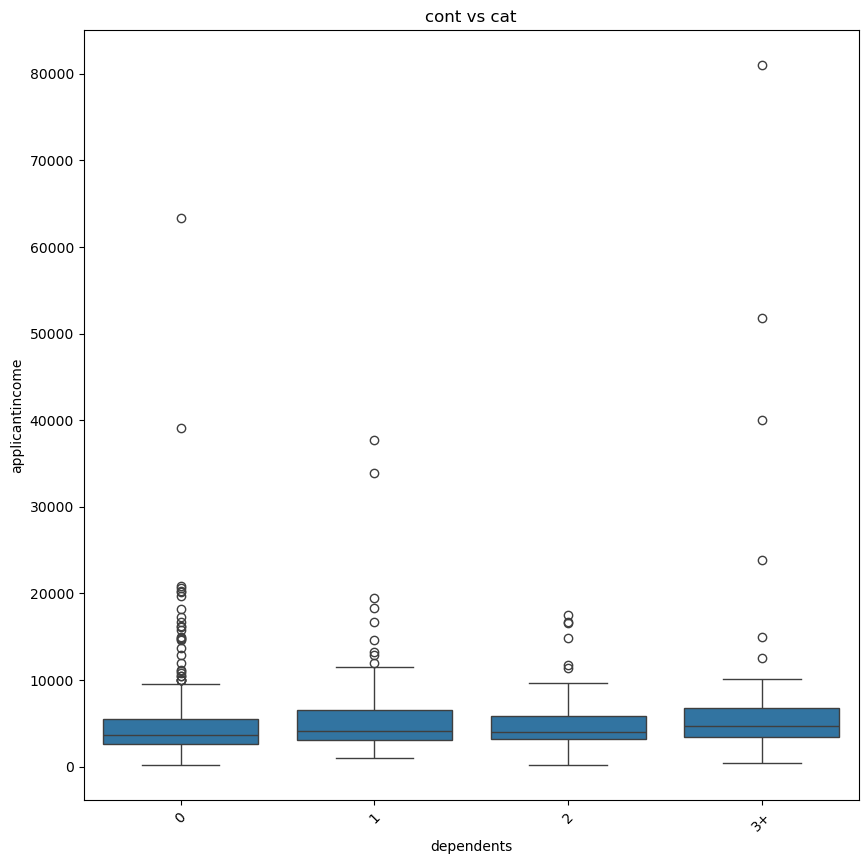

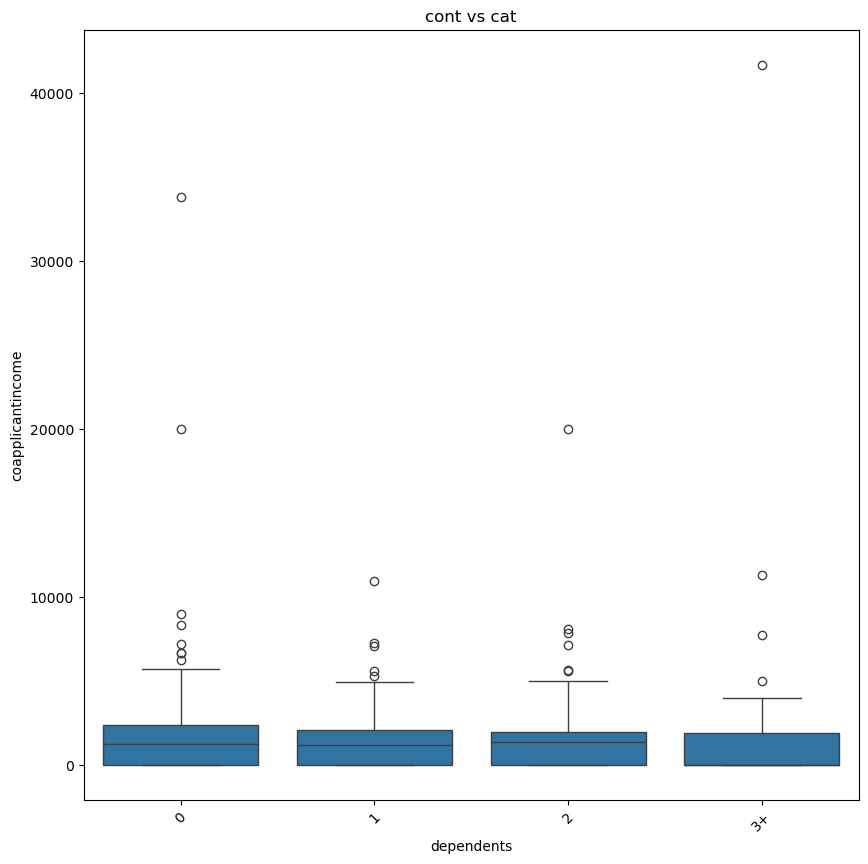

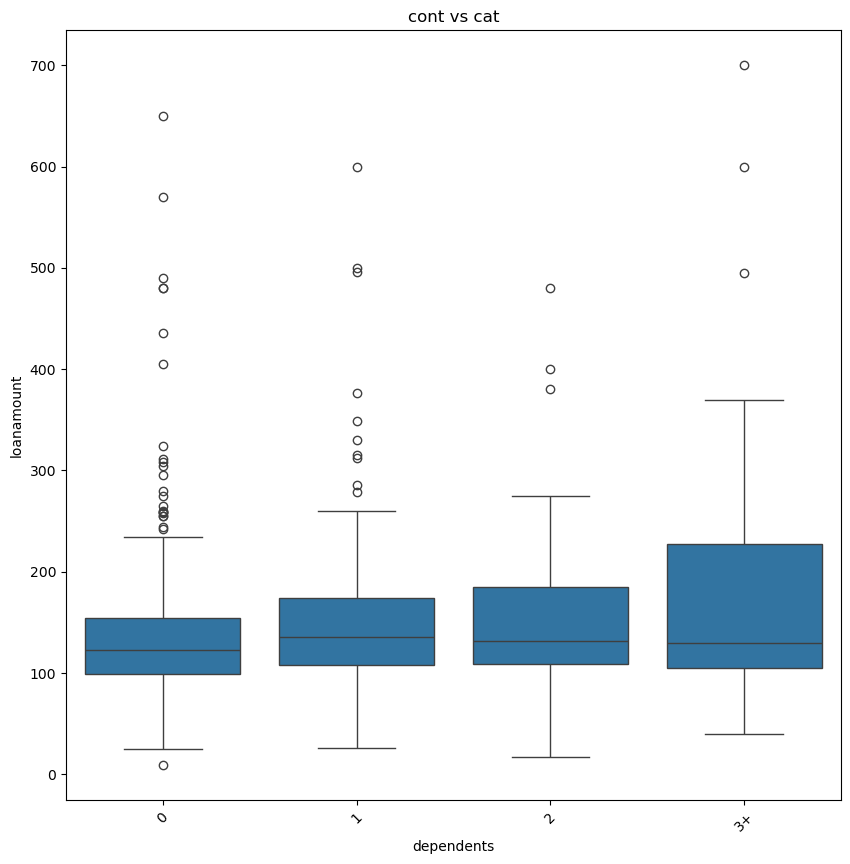

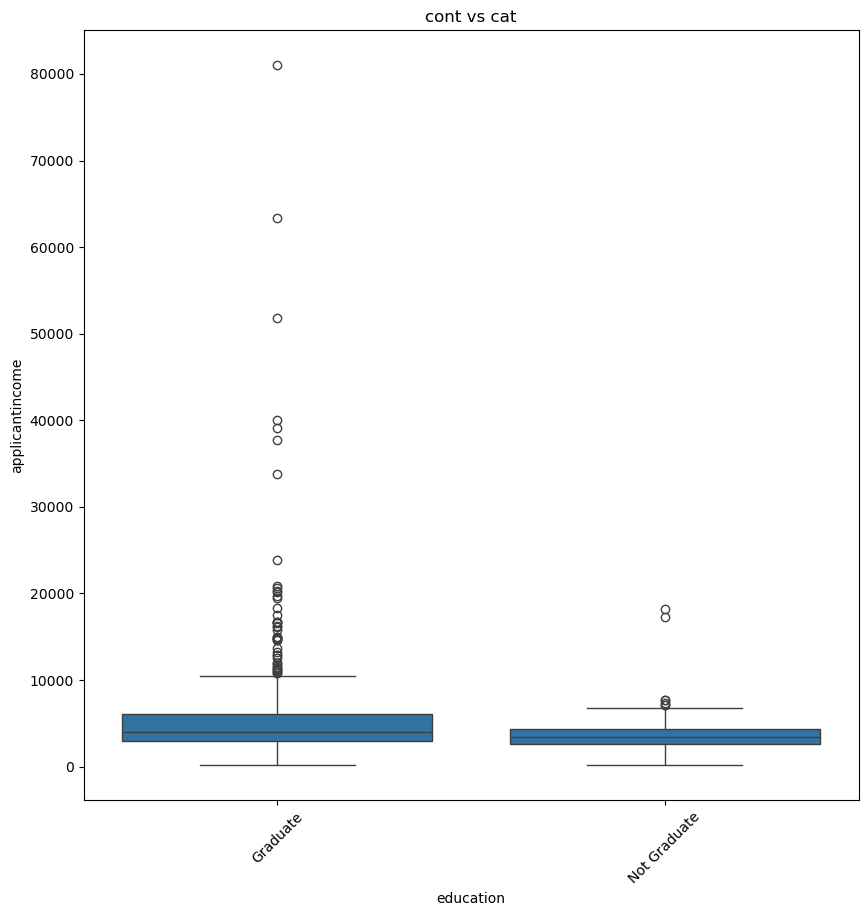

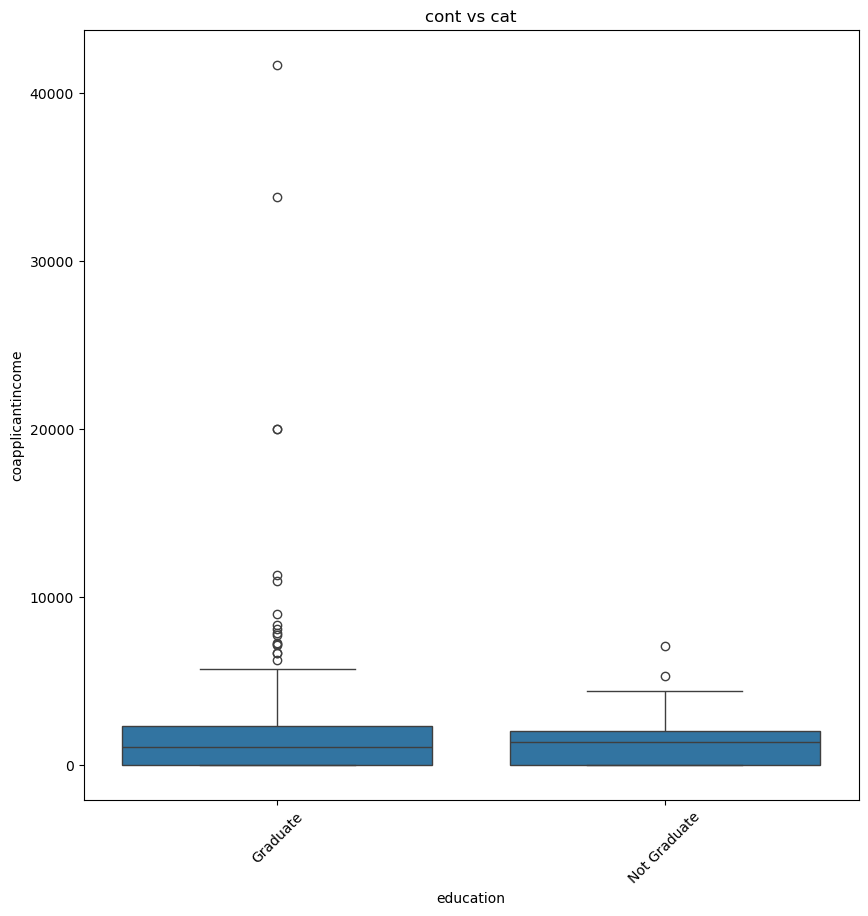

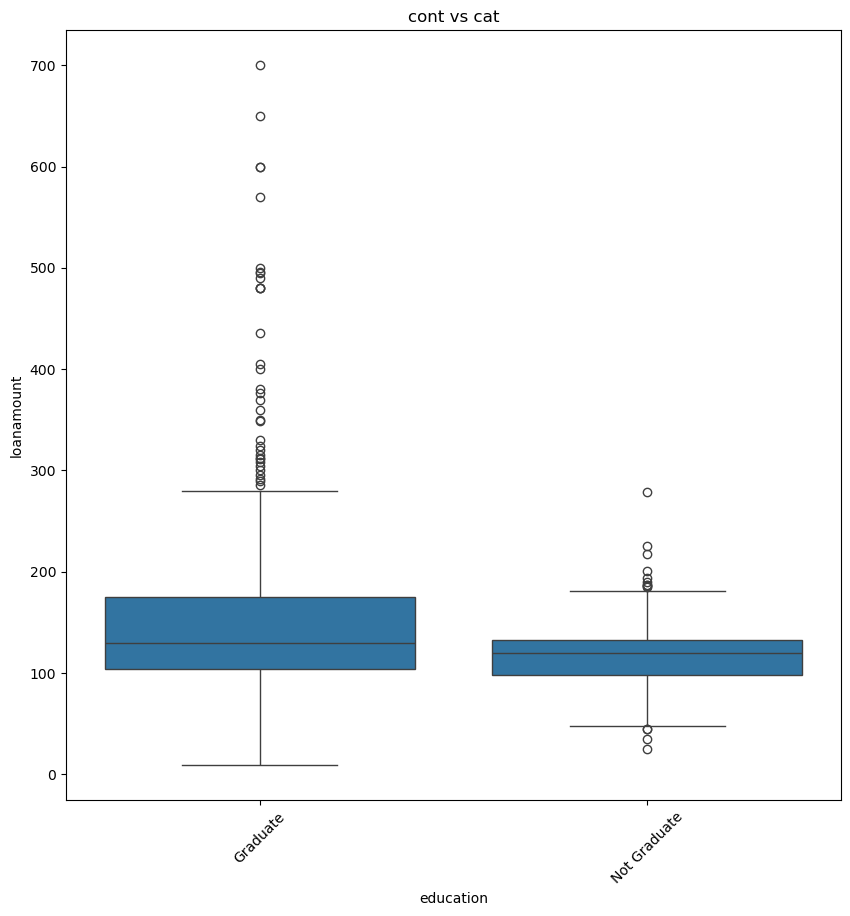

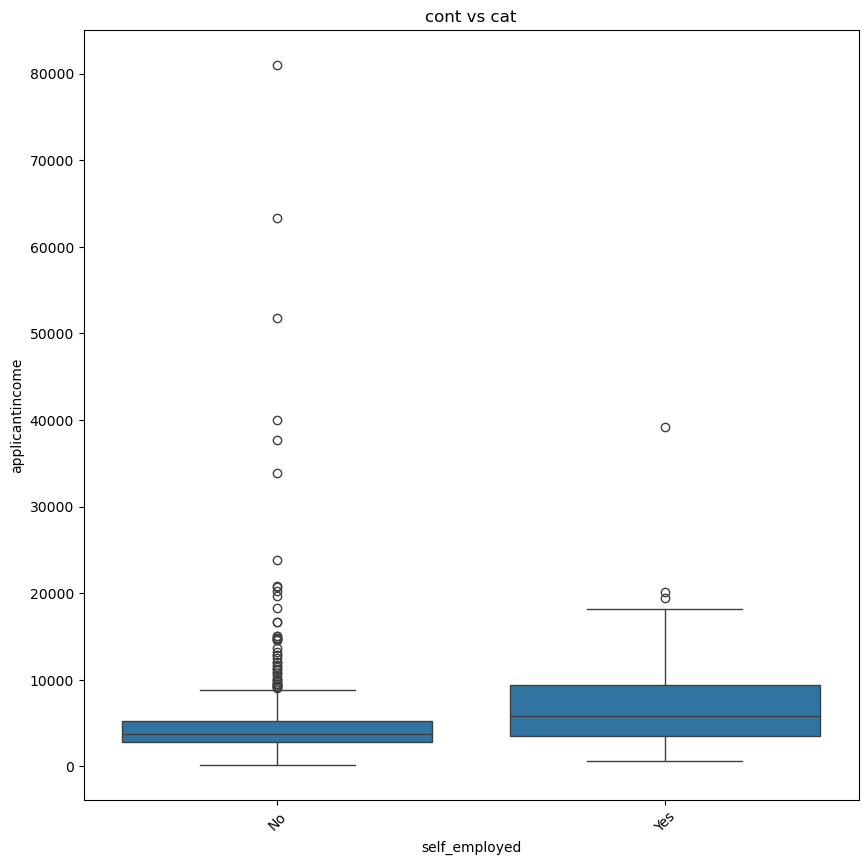

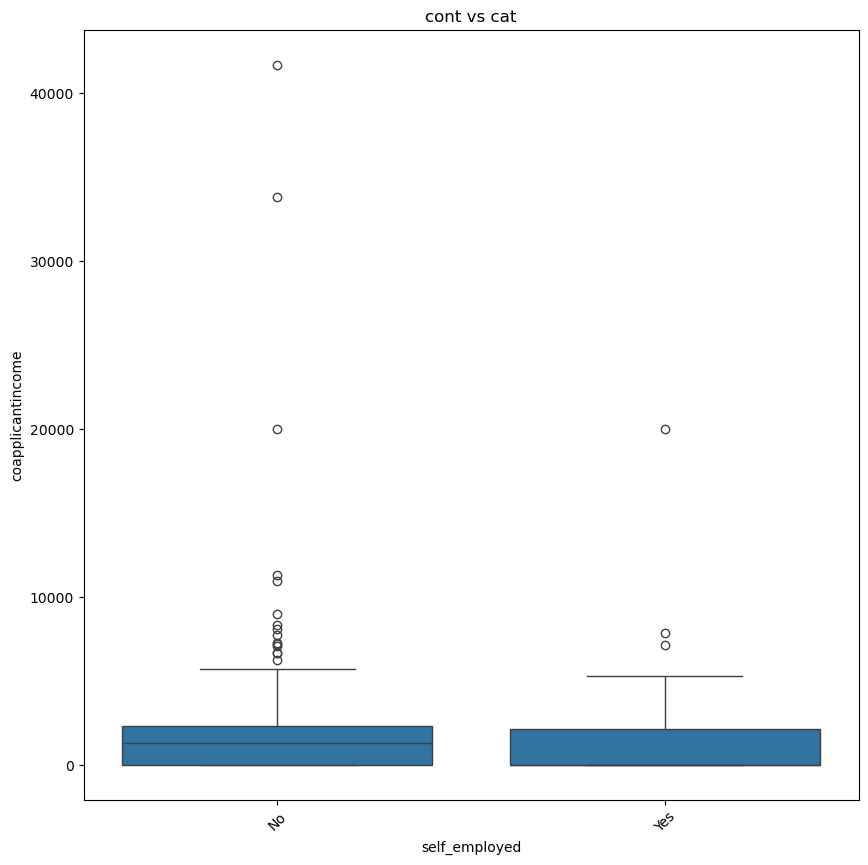

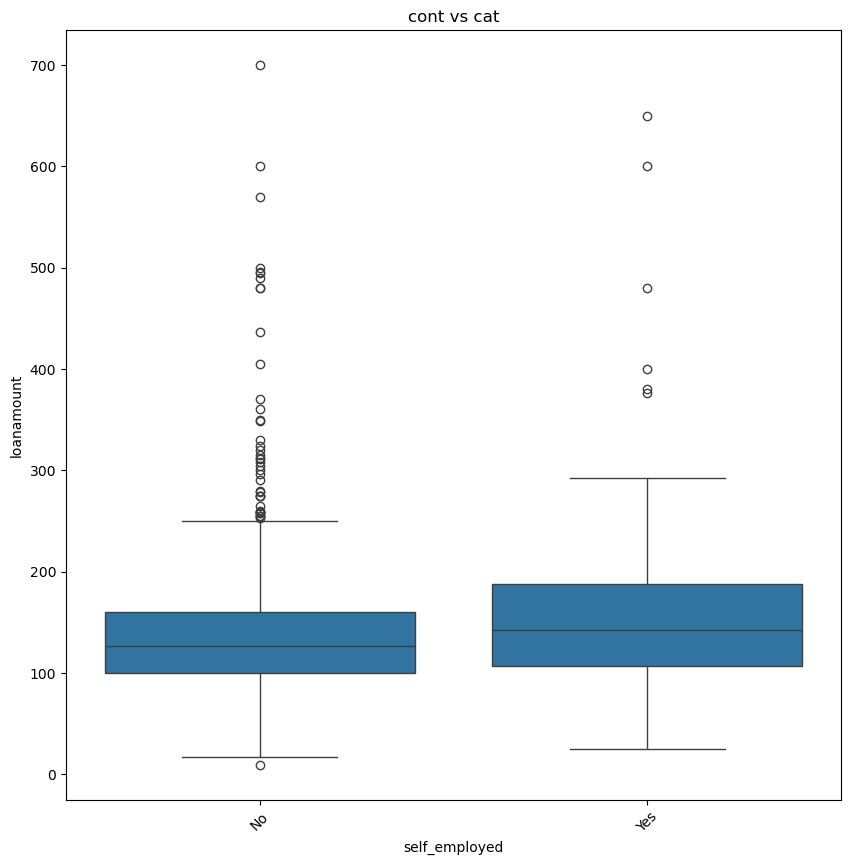

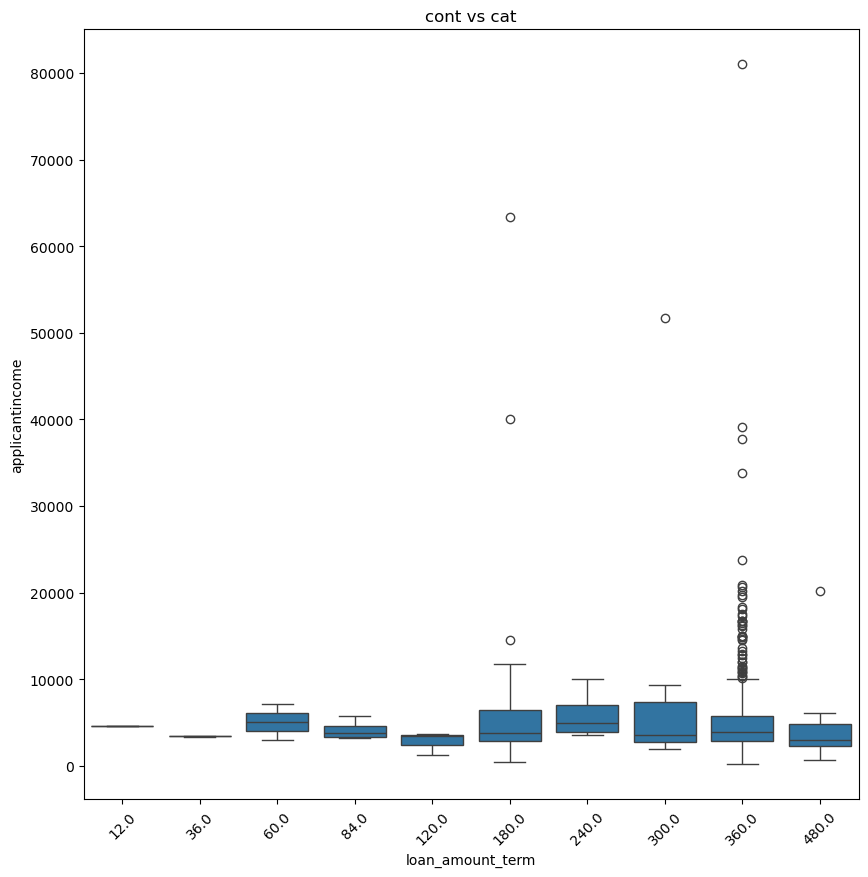

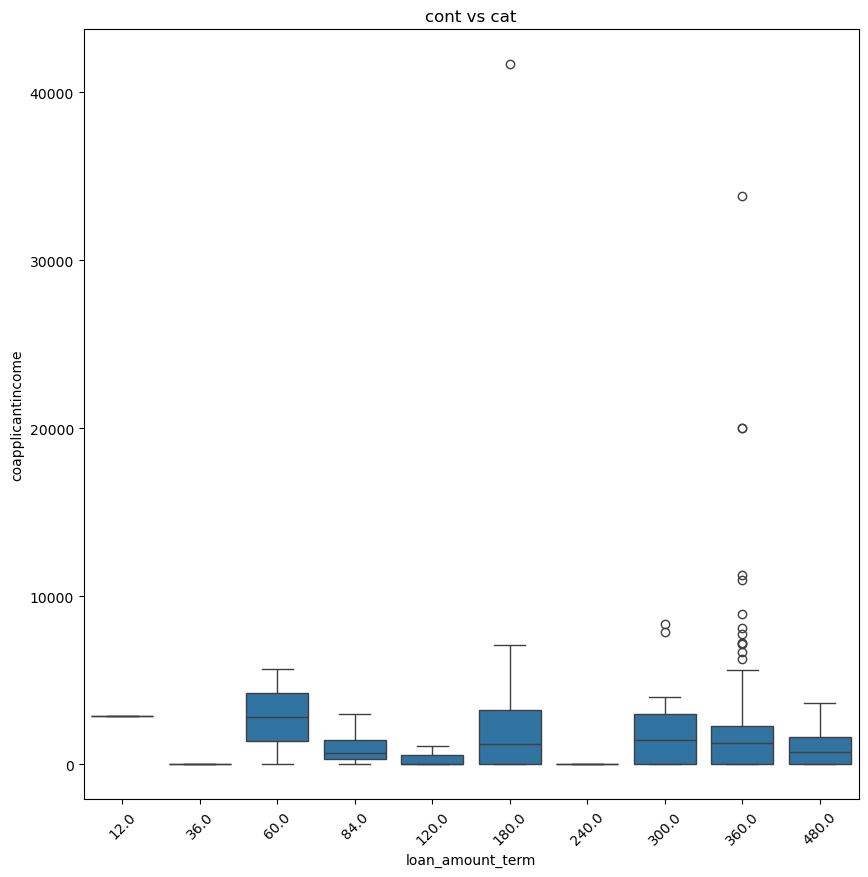

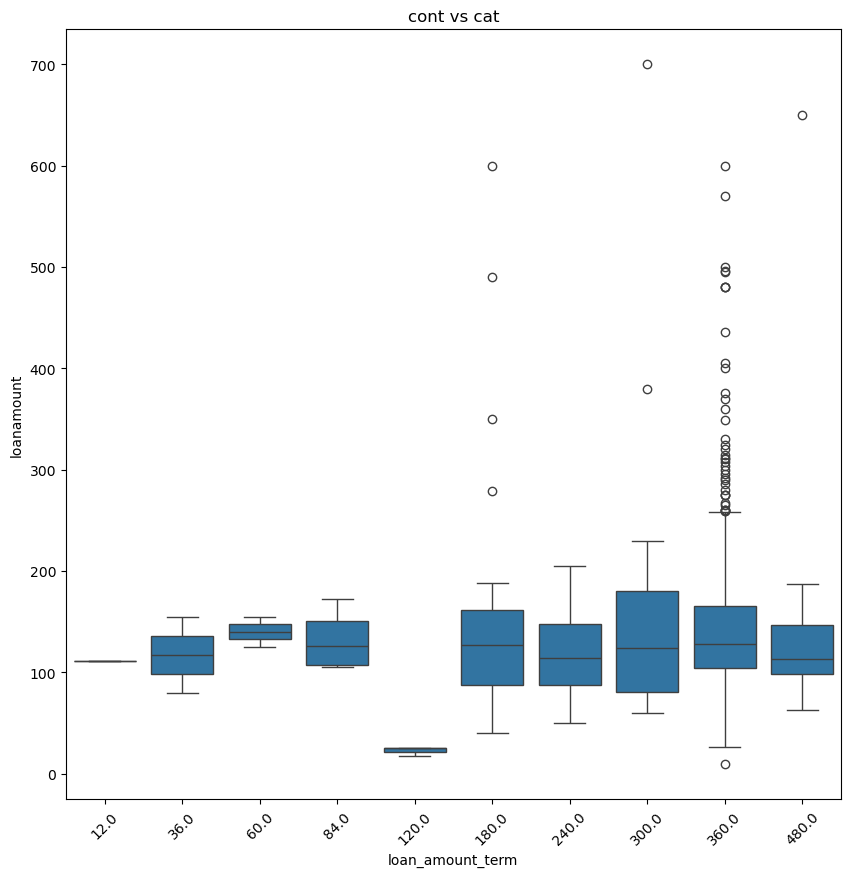

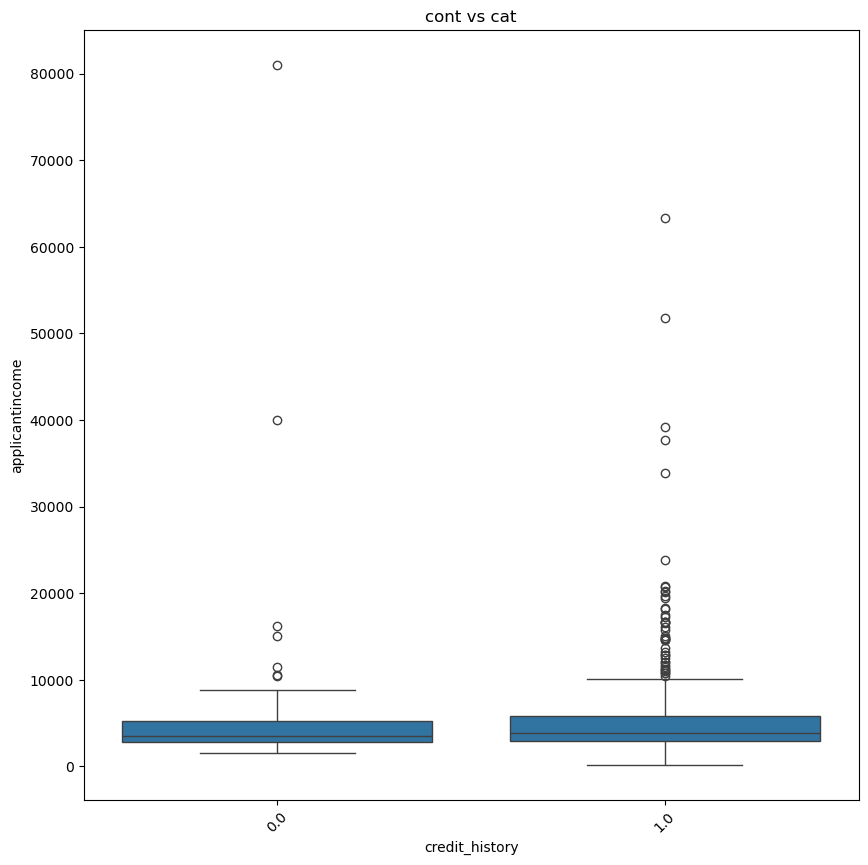

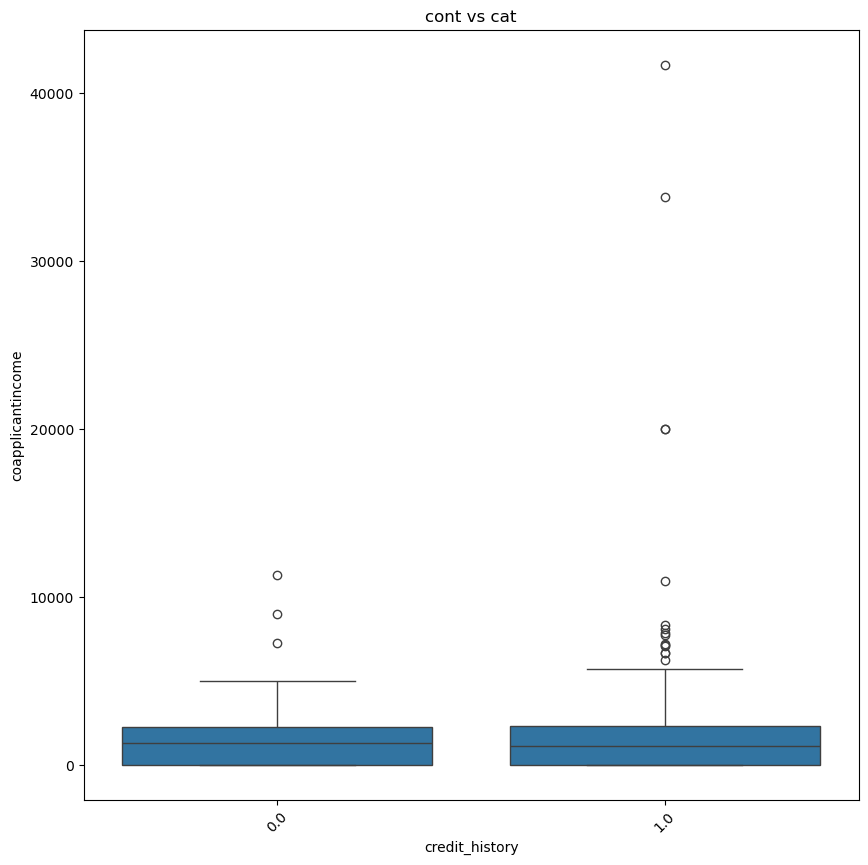

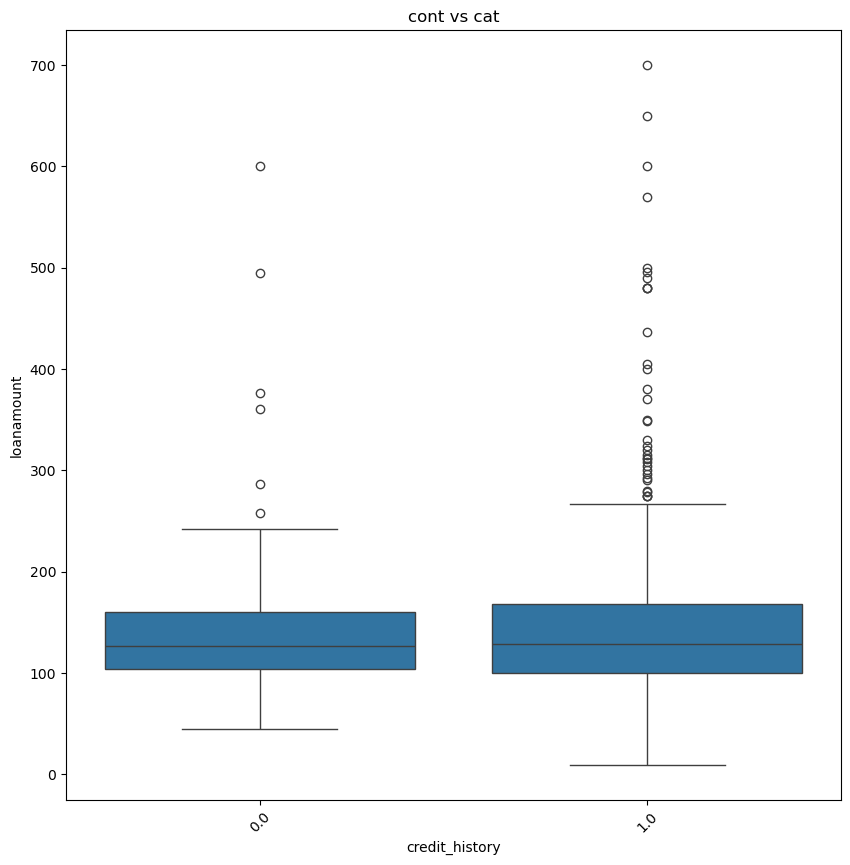

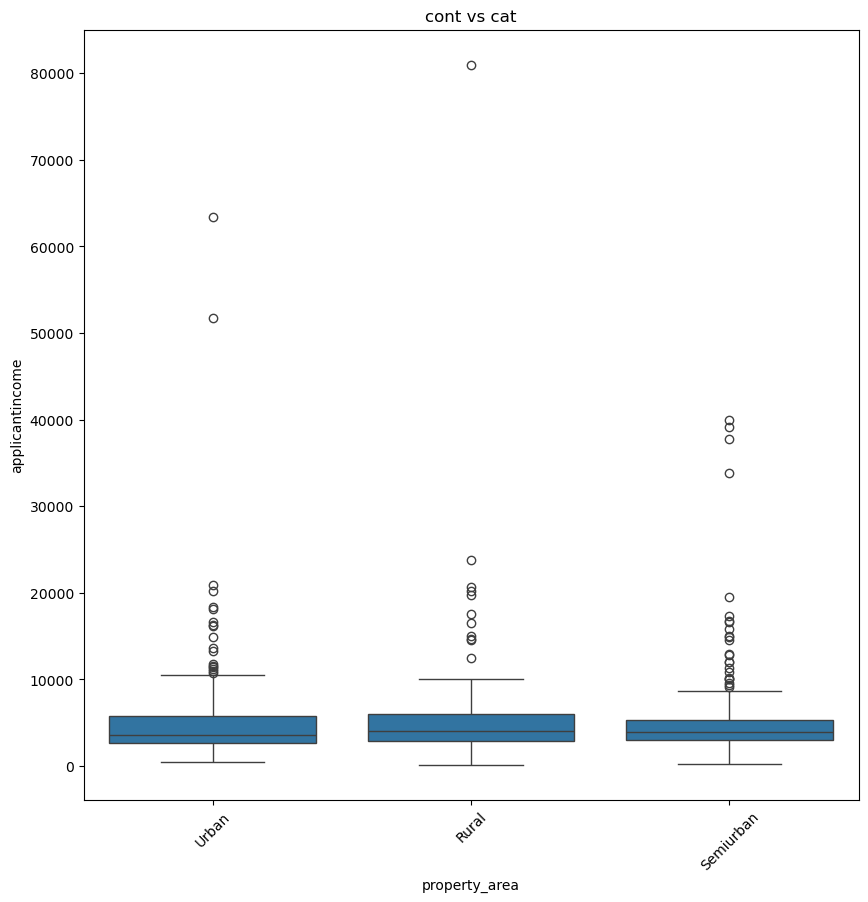

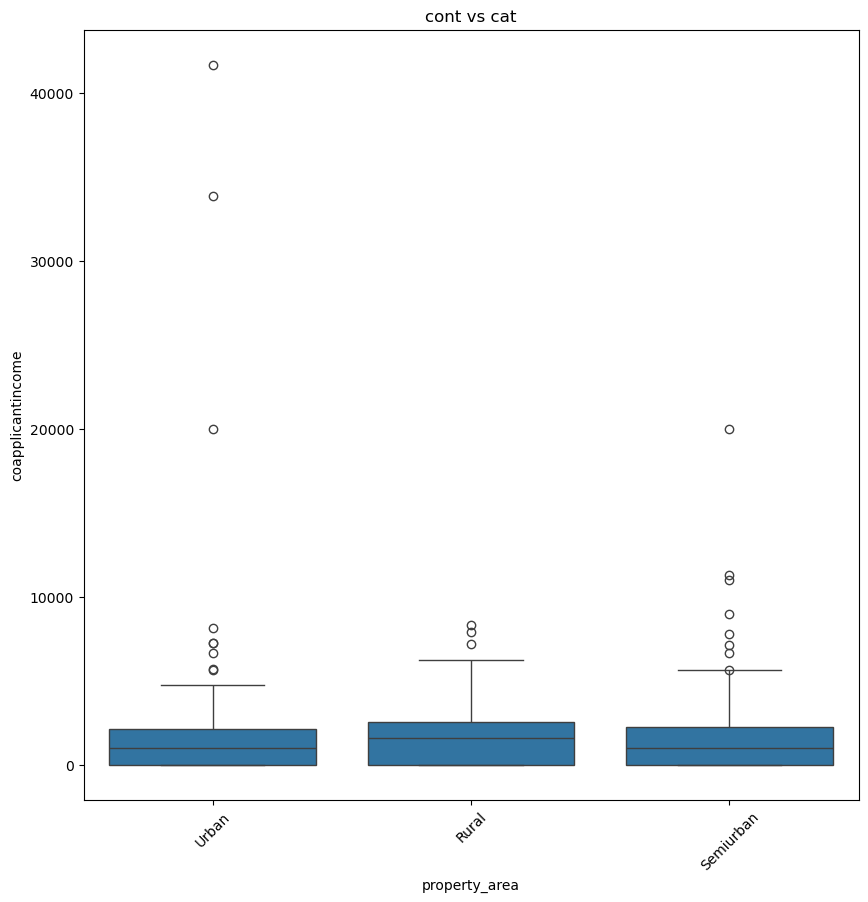

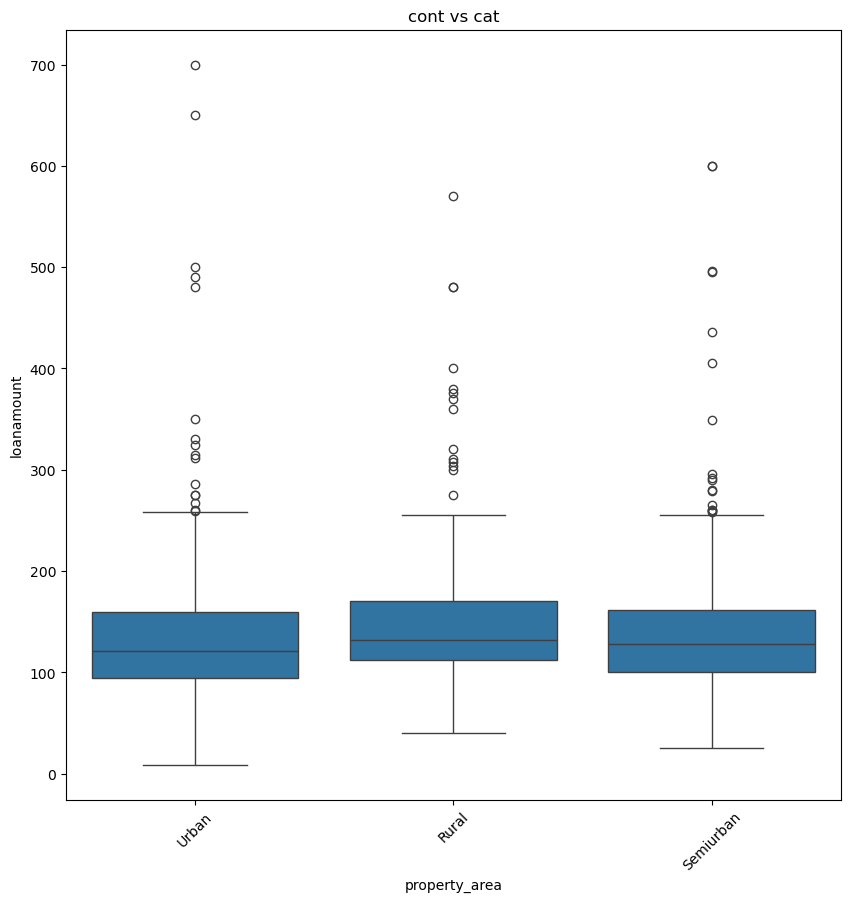

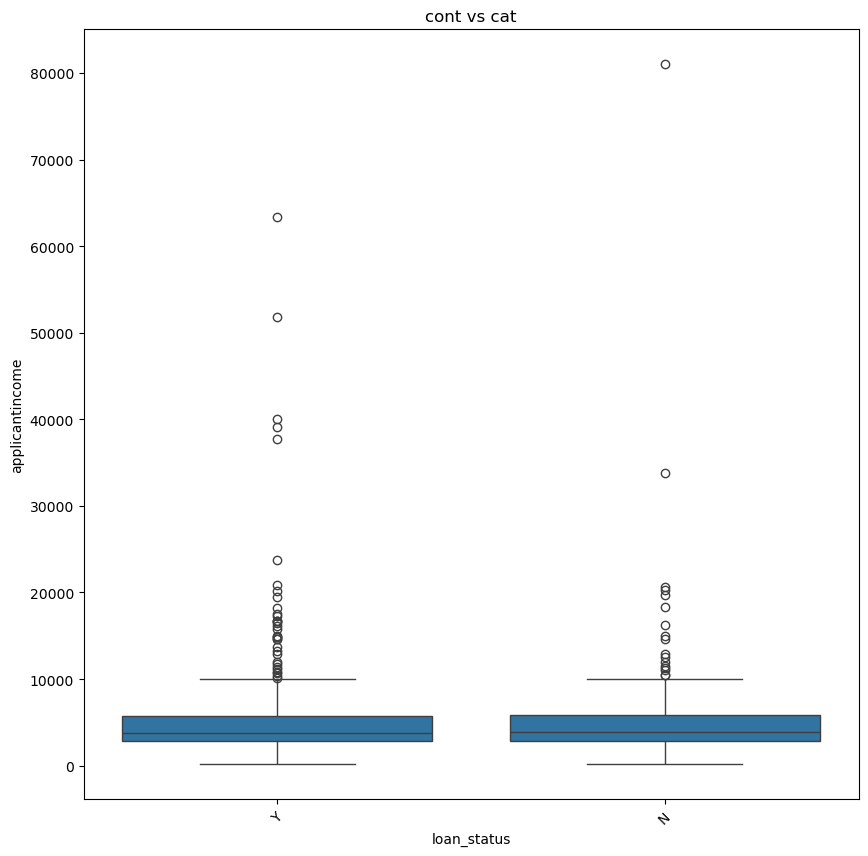

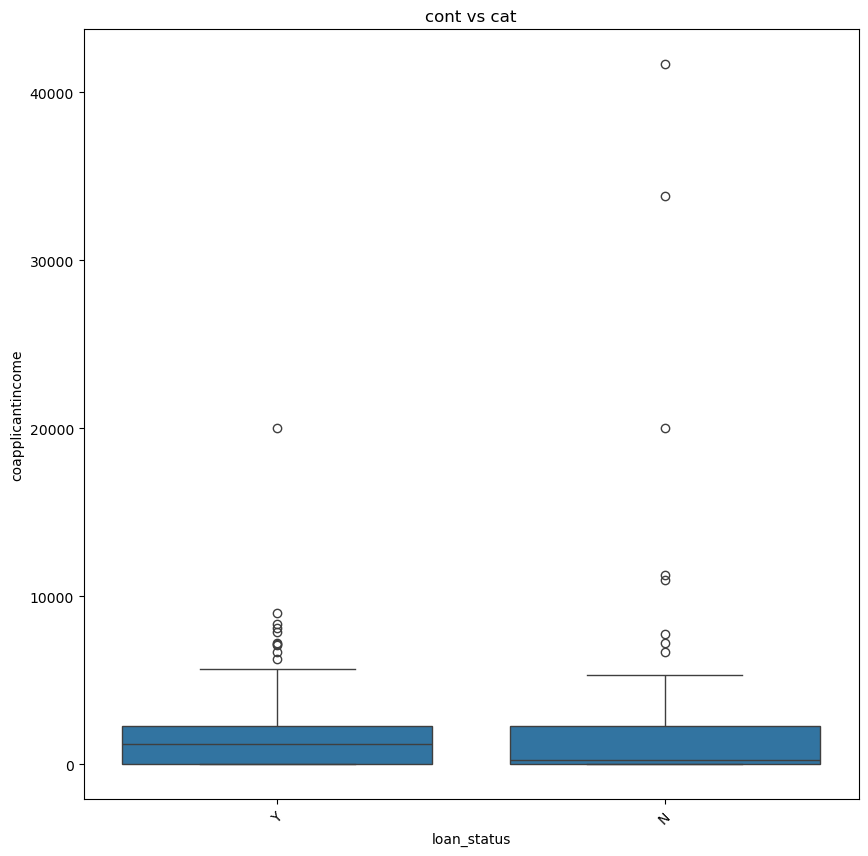

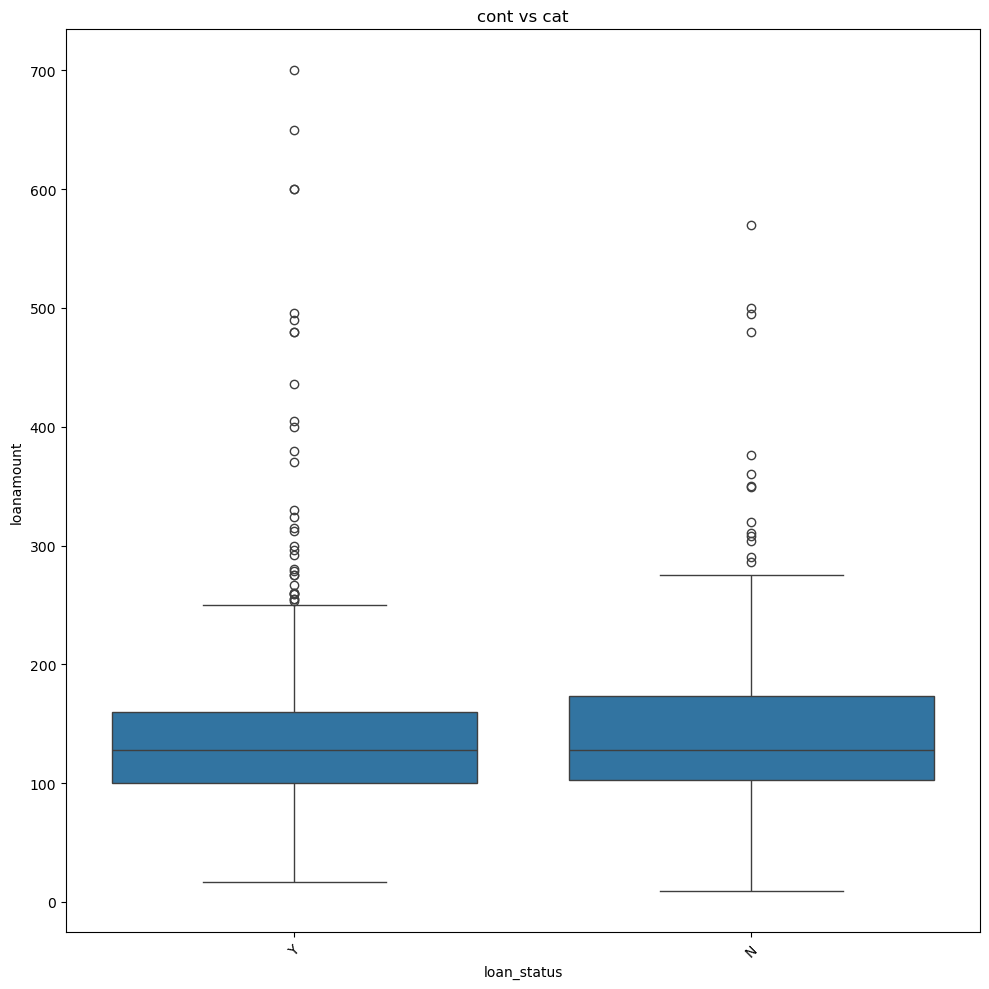

In [87]:
for cat in df_cat:
    for cont in df_cont:
        
        plt.figure(figsize=(10, 10))
        sns.boxplot(x=cat, y=cont, data=df)
        plt.title("cont vs cat")
        plt.xlabel(cat)
        plt.ylabel(cont)
        plt.xticks(rotation=45)
plt.tight_layout()

### Education vs Applicant Income

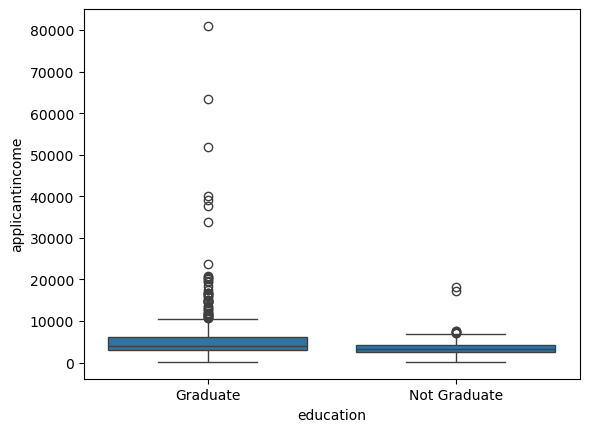

In [89]:
sns.boxplot(
    data=df,
    x="education",
    y="applicantincome"
)
plt.show()

### Property Area vs Loan Amount

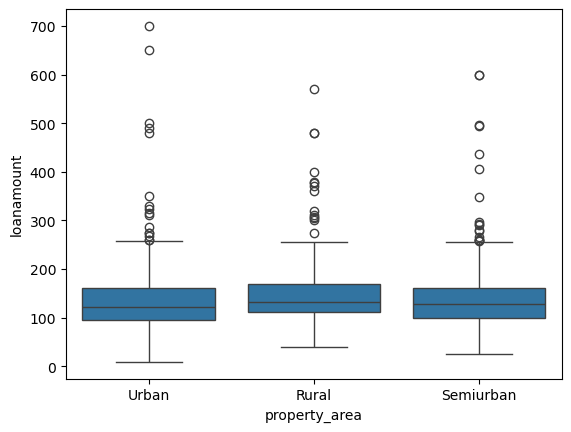

In [91]:
sns.boxplot(
    data=df,
    x="property_area",
    y="loanamount"
)
plt.show()

### Credit History vs Loan Amount

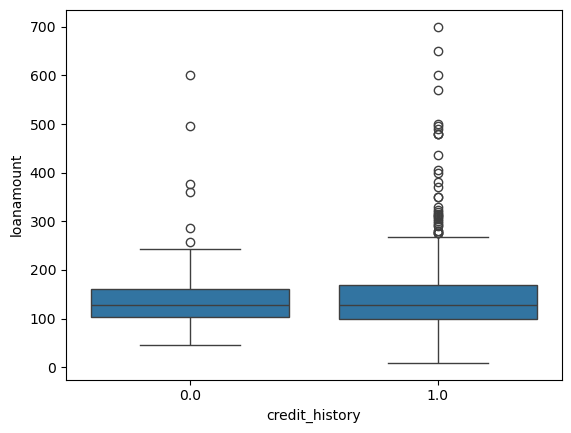

In [93]:
sns.boxplot(
    data=df,
    x="credit_history",
    y="loanamount"
)
plt.show()

### Married vs Applicant Income

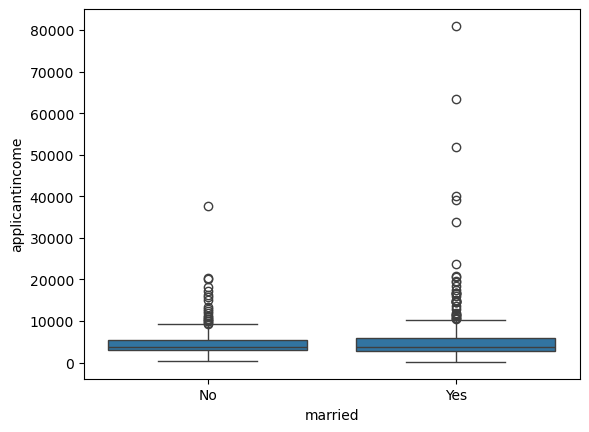

In [95]:
sns.boxplot(
    data = df,
    x = "married",
    y = "applicantincome"
)
plt.show()

## 4. Continuous × Continuous

### Applicant Income vs Loan Amount

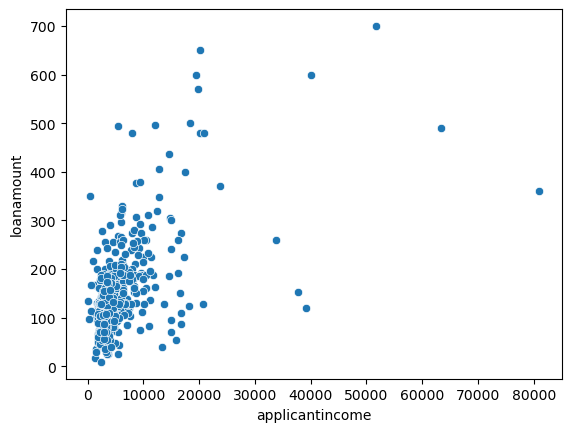

In [98]:
sns.scatterplot(
    data=df,
    x="applicantincome",
    y="loanamount"
)
plt.show()

In [99]:
df["applicantincome"].corr(df["loanamount"])

0.5651805176233123

### Coapplicant Income vs Loan Amount

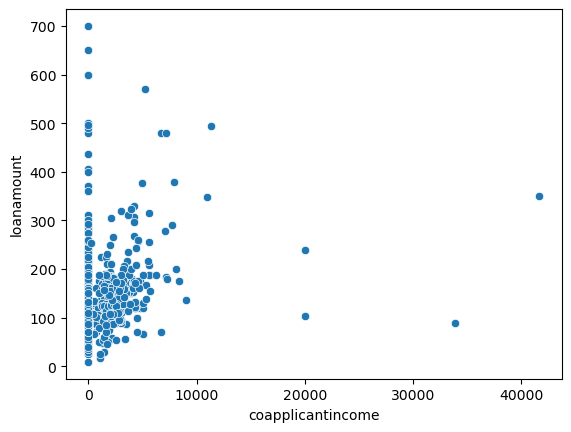

In [101]:
sns.scatterplot(
    data=df,
    x="coapplicantincome",
    y="loanamount"
)
plt.show()

In [102]:
df["coapplicantincome"].corr(df["loanamount"])

0.1892177819666254

### Applicant Income vs Coapplicant Income

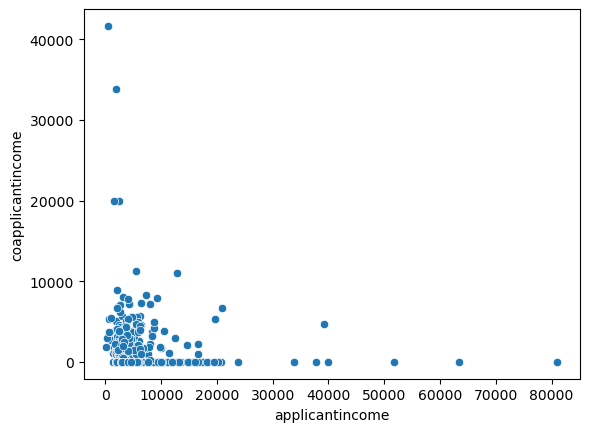

In [104]:
sns.scatterplot(
    data=df,
    x="applicantincome",
    y="coapplicantincome"
)
plt.show()

In [105]:
df["applicantincome"].corr(df["coapplicantincome"])

-0.11660458122889966

## 5. Correlation Matrix

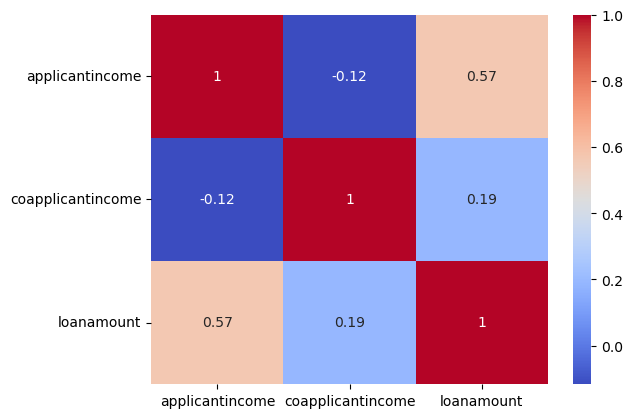

In [107]:
continuous_cols = [
    "applicantincome",
    "coapplicantincome",
    "loanamount"
]

corr = df[continuous_cols].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm"
)

plt.show()